In [1]:
import evds as e
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import month_plot, quarter_plot
import statsmodels.api as sm

with open("C:/Users/merty/Desktop/evds.txt", "r") as file:
    api = file.read()

In [2]:
evds = e.evdsAPI(api)

In [3]:
kat = evds.main_categories
alt = evds.get_sub_categories(36)
seri = evds.get_series("bie_sgegi")
veri = evds.get_data(["TP.SGEGI.K1"], startdate="10-02-2006", enddate="10-02-2026")
veri.rename(columns={
    "TP_SGEGI_K1" : "TurizmGelir"
}, inplace=True)
tarih = pd.date_range("2006-2", periods=len(veri), freq="ME")
veri.set_index("Tarih", inplace=True)
veri.index = pd.to_datetime(veri.index)

In [4]:
s = seasonal_decompose(veri)

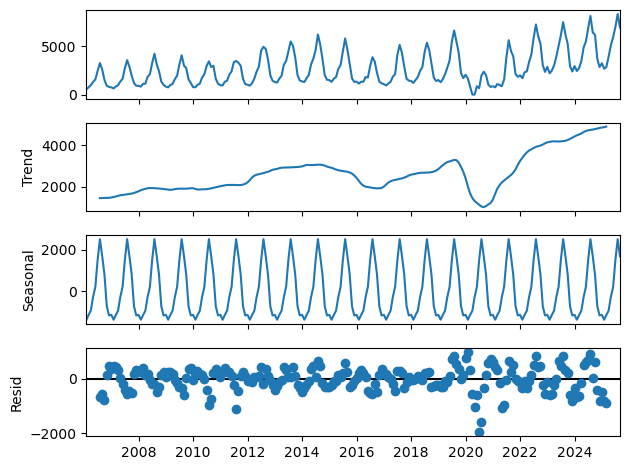

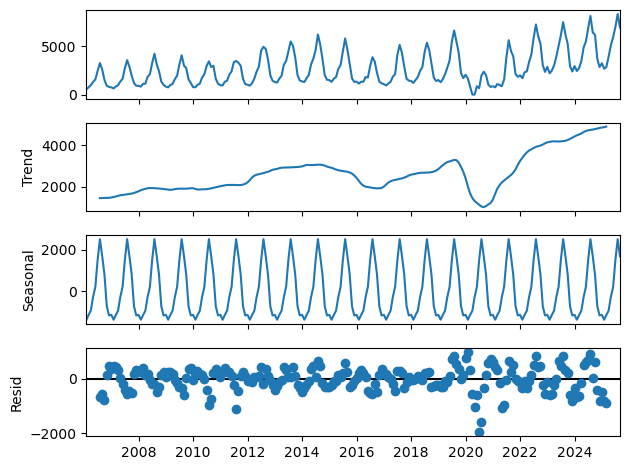

In [5]:
s.plot()

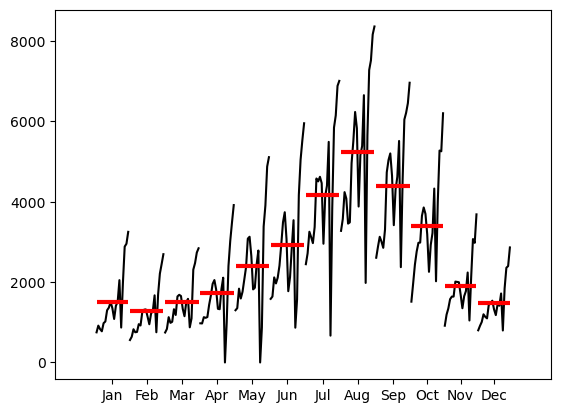

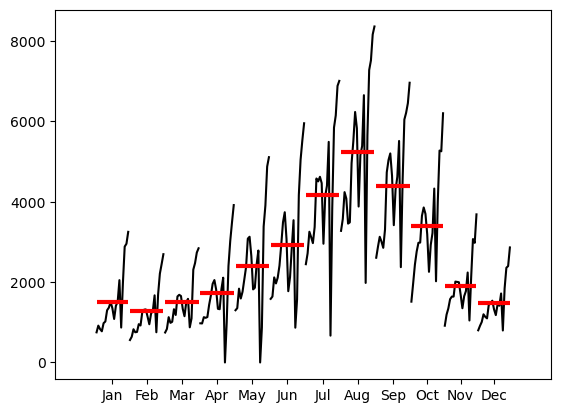

In [6]:
month_plot(veri)

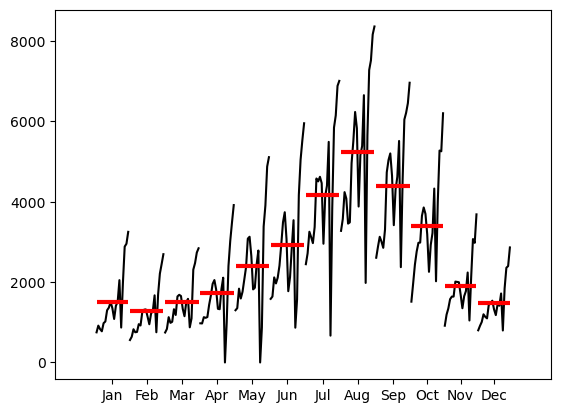

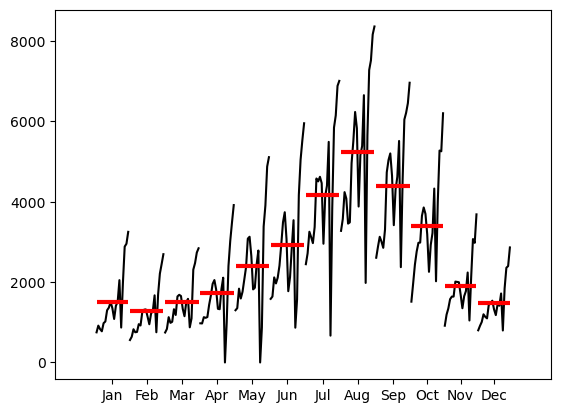

In [13]:
veri_aylık = veri.resample("ME").mean() # çeyreklik zaman dilimleri için veri üretme.
month_plot(veri_aylık)

In [14]:
veri_aylık["Aylık"] = veri_aylık.index.month
dummy = pd.get_dummies(veri_aylık["Aylık"], prefix="Aylık", dtype=int, drop_first=False)
veri_aylık = pd.concat([veri_aylık, dummy], axis=1)


In [15]:
veri_aylık

,TurizmGelir,Aylık,Aylık_1,Aylık_2,Aylık_3,Aylık_4,Aylık_5,Aylık_6,Aylık_7,Aylık_8,Aylık_9,Aylık_10,Aylık_11,Aylık_12
Tarih,,,,,,,,,,,,,,
2006-02-28,559.0,2,0,1,0,0,0,0,0,0,0,0,0,0
2006-03-31,746.0,3,0,0,1,0,0,0,0,0,0,0,0,0
2006-04-30,975.0,4,0,0,0,1,0,0,0,0,0,0,0,0
2006-05-31,1300.0,5,0,0,0,0,1,0,0,0,0,0,0,0
2006-06-30,1583.0,6,0,0,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-05-31,5109.0,5,0,0,0,0,1,0,0,0,0,0,0,0
2025-06-30,5953.0,6,0,0,0,0,0,1,0,0,0,0,0,0
2025-07-31,7008.0,7,0,0,0,0,0,0,1,0,0,0,0,0


In [16]:
x = veri_aylık.drop(columns=["TurizmGelir", "Aylık"])
y = veri_aylık["TurizmGelir"]

In [19]:
x = sm.add_constant(x)
model = sm.OLS(y,x).fit()

In [20]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            TurizmGelir   R-squared:                       0.574
Model:                            OLS   Adj. R-squared:                  0.553
Method:                 Least Squares   F-statistic:                     27.39
Date:                Wed, 11 Feb 2026   Prob (F-statistic):           1.05e-35
Time:                        07:29:54   Log-Likelihood:                -1991.4
No. Observations:                 236   AIC:                             4007.
Df Residuals:                     224   BIC:                             4048.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2454.5170     68.963     35.592      0.000    2318.618    2590.416
Aylık_1     -938.9381    251.763     -3.729      0.000   -1435.065    -442.811
Aylık_2    -1185.7670    245.872     -4.823      0.000   -1670.285    -701.249
Aylık_3     -949.4170    245.872     -3.861      0.000   -1433.935    -464.899
Aylık_4     -721.6170    245.872     -2.935      0.004   -1206.135    -237.099
Aylık_5      -44.8670    245.872     -0.182      0.855    -529.385     439.651
Aylık_6      469.2830    245.872      1.909      0.058     -15.235     953.801
Aylık_7     1716.7830    245.872      6.982      0.000    1232.265    2201.301
Aylık_8     2779.3330    245.872     11.304      0.000    2294.815    3263.851
Aylık_9     1936.4330    245.872      7.876      0.000    1451.915    2420.951
Aylık_10     940.9567    251.763      3.737      0.000     444.830    1437.083
Aylık_11    -562.9381    251.763     -2.236      0.026   -1059.065     -66.811
Aylık_12    -984.7275    251.763     -3.911      0.000   -1480.854    -488.601
==============================================================================
Omnibus:                       11.227   Durbin-Watson:                   0.114
Prob(Omnibus):                  0.004   Jarque-Bera (JB):               12.254
Skew:                           0.440   Prob(JB):                      0.00218
Kurtosis:                       3.688   Cond. No.                     9.69e+15
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 2.72e-30. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""